pandas 2.2.3 | scikit-learn 1.6.1
Archivo descargado exitosamente desde el espejo de GitHub
Dimensiones originales (filas, columnas): (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Filas duplicadas: 0
Valores de Outcome: [np.int64(0), np.int64(1)]
Columnas tipo identificador: ninguna


,ceros,% del total
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4



Faltantes tras la conversión:


,faltantes,%
Pregnancies,0,0.0
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4
DiabetesPedigreeFunction,0,0.0
Age,0,0.0
Outcome,0,0.0


,atípicos,% de válidos
Pregnancies,4.0,0.5
Glucose,0.0,0.0
BloodPressure,14.0,1.9
SkinThickness,3.0,0.6
Insulin,24.0,6.1
BMI,8.0,1.1
DiabetesPedigreeFunction,29.0,3.8
Age,9.0,1.2


,registros,%
Outcome,,
0 - Sin diabetes,500,65.1
1 - Con diabetes,268,34.9


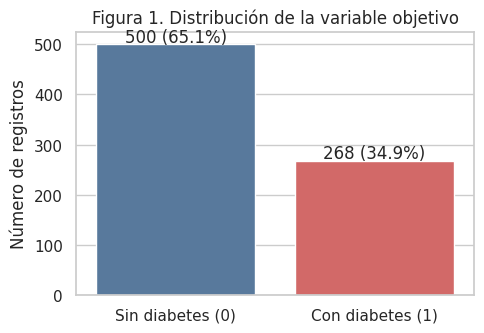

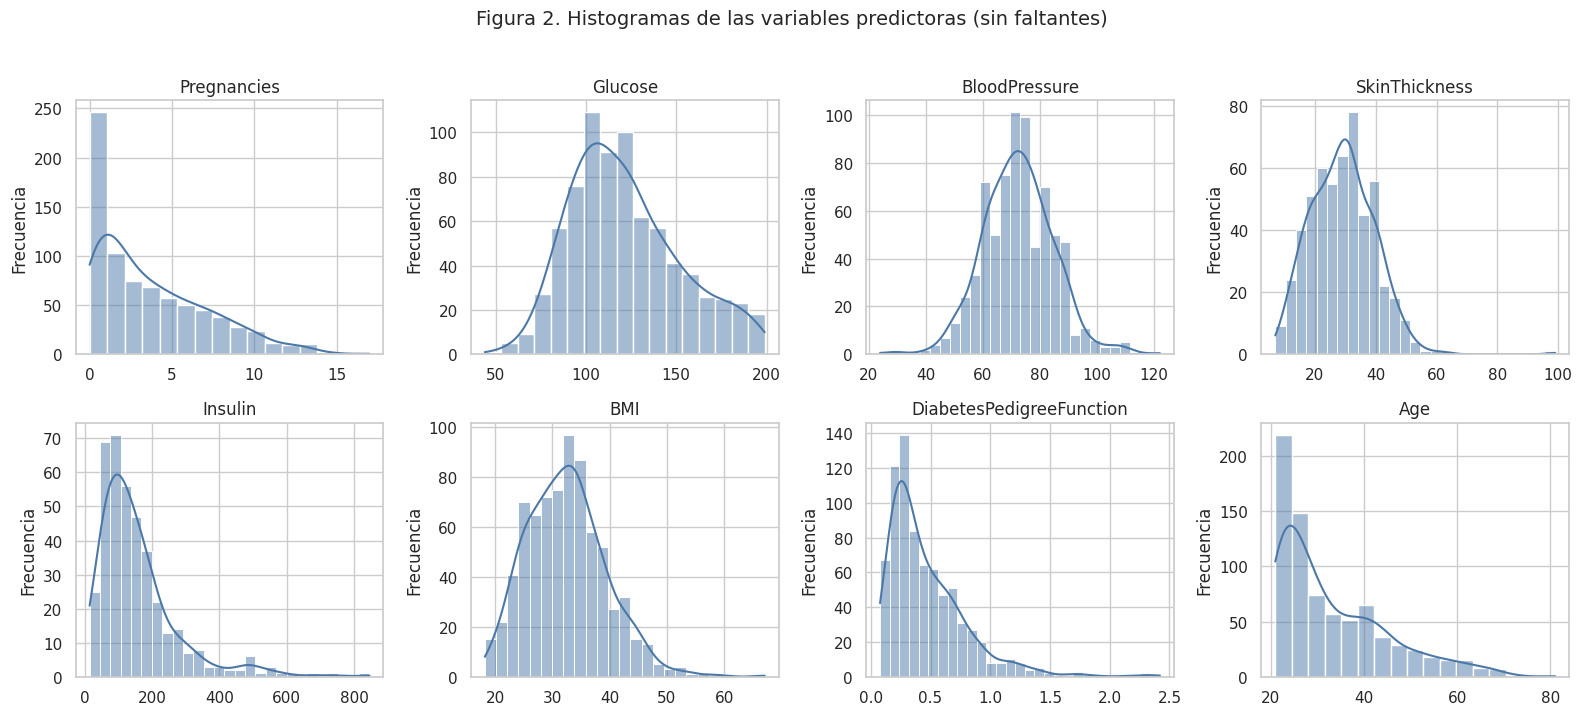

Outcome                               0       1
Pregnancies              mean      3.30    4.87
                         median    2.00    4.00
Glucose                  mean    110.64  142.32
                         median  107.00  140.00
BloodPressure            mean     70.88   75.32
                         median   70.00   74.50
SkinThickness            mean     27.24   33.00
                         median   27.00   32.00
Insulin                  mean    130.29  206.85
                         median  102.50  169.50
BMI                      mean     30.86   35.41
                         median   30.10   34.30
DiabetesPedigreeFunction mean      0.43    0.55
                         median    0.34    0.45
Age                      mean     31.19   37.07
                         median   27.00   36.00

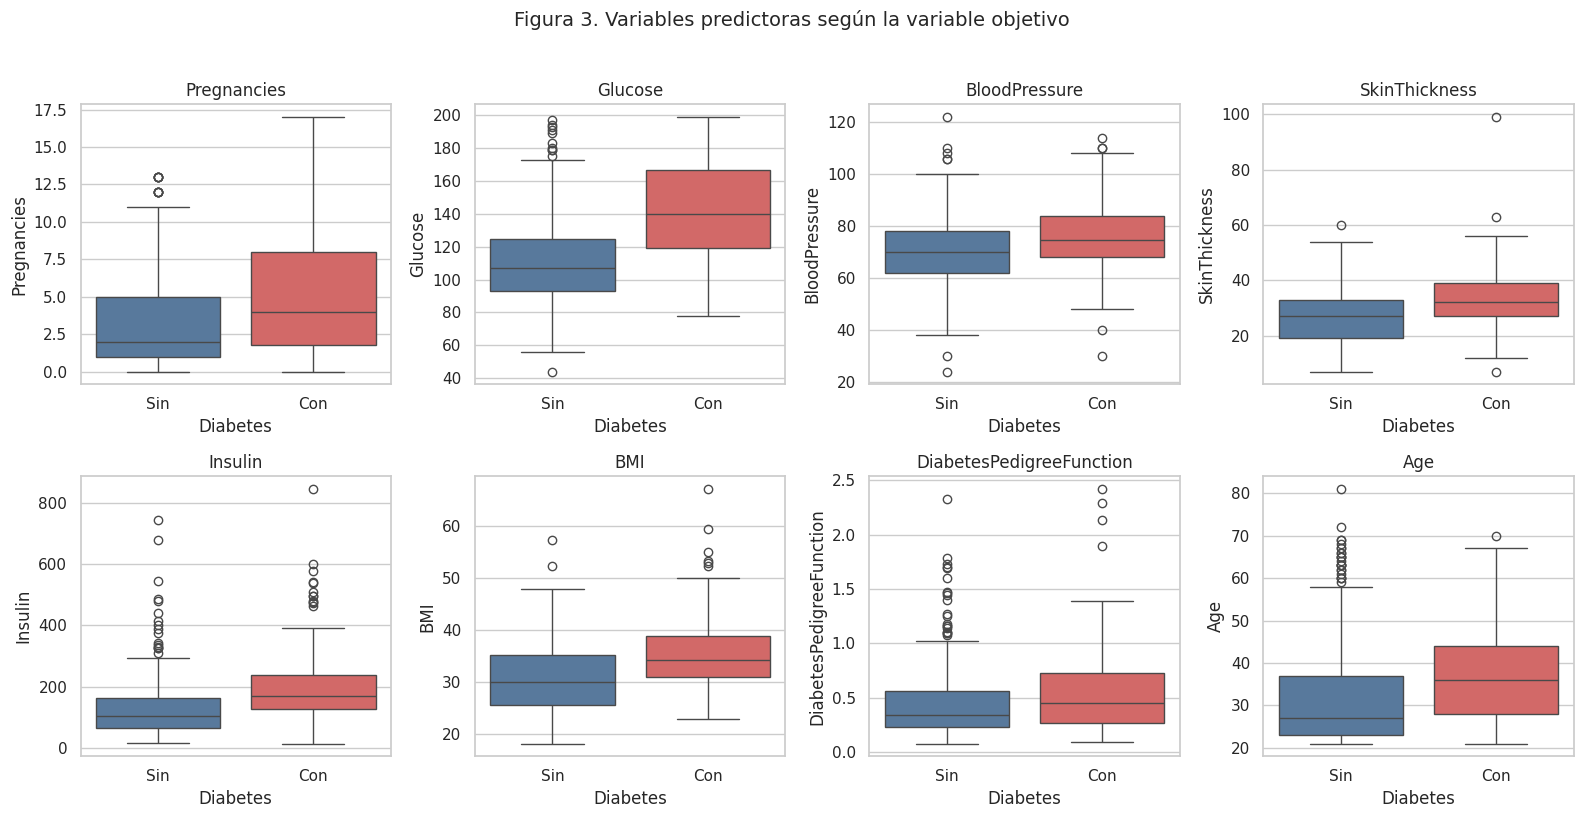

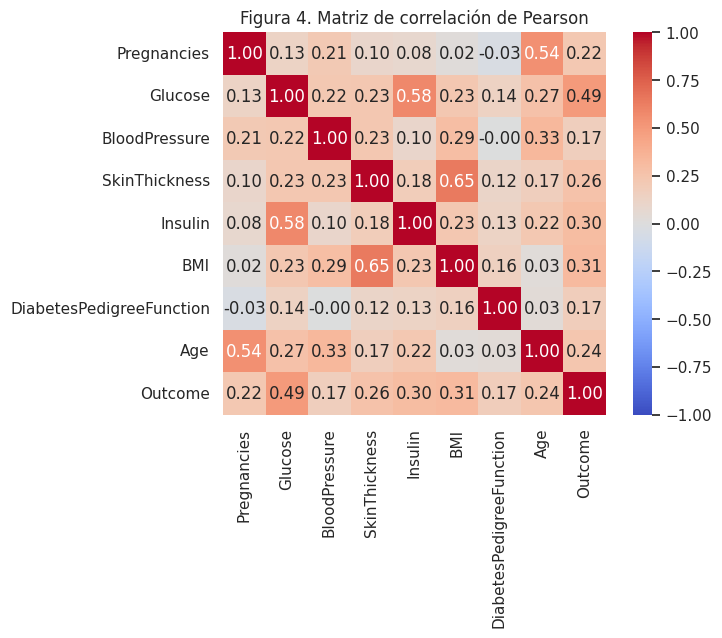

,Accuracy,Precision,Recall,F1,ROC-AUC
Línea base (mayoritaria),0.649,0.000,0.000,0.000,0.500
Regresión logística,0.708,0.600,0.500,0.545,0.813
Árbol de decisión,0.792,0.696,0.722,0.709,0.801


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

SEED = 42
print("pandas", pd.__version__, "| scikit-learn", __import__("sklearn").__version__)

# 1. Carga del dataset
RUTAS = ["diabetes.csv", "data/diabetes.csv", "/content/diabetes.csv",
         "/kaggle/input/pima-indians-diabetes-database/diabetes.csv"]
ruta = next((r for r in RUTAS if os.path.exists(r)), None)

if ruta is not None:
    df_raw = pd.read_csv(ruta)
    print("Archivo usado:", ruta)
else:
    try:
        # Descarga desde un repositorio público en GitHub para evitar errores de autenticación de Kaggle
        url_espejo = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
        columnas_pima = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
        df_raw = pd.read_csv(url_espejo, names=columnas_pima)
        print("Archivo descargado exitosamente desde el espejo de GitHub")
    except Exception as e:
        raise FileNotFoundError(
            "No se pudo cargar el archivo localmente ni descargar el espejo. "
            "Por favor, suba 'diabetes.csv' a su entorno de ejecución.") from e

print("Dimensiones originales (filas, columnas):", df_raw.shape)
display(df_raw.head())

# 2. Preparación de los datos (1.2)
df_raw.info()
display(df_raw.describe().T.round(2))

print("Filas duplicadas:", df_raw.duplicated().sum())
print("Valores de Outcome:", sorted(df_raw["Outcome"].unique()))
print("Columnas tipo identificador:",
      [c for c in df_raw.columns if "id" == c.lower() or "name" in c.lower()] or "ninguna")

COLS_CERO_INVALIDO = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
ceros = pd.DataFrame({
    "ceros": (df_raw[COLS_CERO_INVALIDO] == 0).sum(),
    "% del total": ((df_raw[COLS_CERO_INVALIDO] == 0).mean() * 100).round(1),
})
display(ceros)

df = df_raw.drop_duplicates().copy()
df[COLS_CERO_INVALIDO] = df[COLS_CERO_INVALIDO].replace(0, np.nan)

print("\nFaltantes tras la conversión:")
display(pd.DataFrame({"faltantes": df.isna().sum(), "%": (df.isna().mean()*100).round(1)}))

def resumen_outliers(data):
    filas = {}
    for c in data.columns.drop("Outcome"):
        s = data[c].dropna()
        q1, q3 = s.quantile([.25, .75])
        iqr = q3 - q1
        n = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
        filas[c] = {"atípicos": int(n), "% de válidos": round(n/len(s)*100, 1)}
    return pd.DataFrame(filas).T

display(resumen_outliers(df))

# 3. Análisis Exploratorio de Datos (1.3)
conteo = df["Outcome"].value_counts().sort_index()
pct = (conteo / conteo.sum() * 100).round(1)
display(pd.DataFrame({"registros": conteo, "%": pct}).rename(index={0: "0 - Sin diabetes", 1: "1 - Con diabetes"}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="Outcome", ax=ax, palette=["#4C78A8", "#E45756"])
ax.set_xticklabels(["Sin diabetes (0)", "Con diabetes (1)"])
ax.set_title("Figura 1. Distribución de la variable objetivo")
ax.set_xlabel(""); ax.set_ylabel("Número de registros")
for i, v in enumerate(conteo):
    ax.text(i, v + 5, f"{v} ({pct[i]}%)", ha="center")
plt.tight_layout(); plt.show()

FEATURES = [c for c in df.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), FEATURES):
    sns.histplot(df[c].dropna(), kde=True, ax=ax, color="#4C78A8")
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("Frecuencia")
fig.suptitle("Figura 2. Histogramas de las variables predictoras (sin faltantes)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

resumen = df.groupby("Outcome")[FEATURES].agg(
    ["mean", "median"]).round(2).T
display(resumen)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, c in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="Outcome", y=c, ax=ax, palette=["#4C78A8", "#E45756"])
    ax.set_xticklabels(["Sin", "Con"]); ax.set_xlabel("Diabetes"); ax.set_title(c)
fig.suptitle("Figura 3. Variables predictoras según la variable objetivo", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

corr = df.corr(numeric_only=True)
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Figura 4. Matriz de correlación de Pearson")
plt.tight_layout(); plt.show()

# 4. Selección y entrenamiento de modelos (1.4.1)
X = df.drop(columns="Outcome")
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

modelos = {
    "Línea base (mayoritaria)": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Regresión logística": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("esc", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
    "Árbol de decisión": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEED))]),
}

for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)

pred_test  = {n: m.predict(X_test) for n, m in modelos.items()}
proba_test = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}

# 5. Evaluación
def metricas(y_real, y_pred, y_proba):
    return {"Accuracy": accuracy_score(y_real, y_pred),
            "Precision": precision_score(y_real, y_pred, zero_division=0),
            "Recall": recall_score(y_real, y_pred, zero_division=0),
            "F1": f1_score(y_real, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_real, y_proba)}

tabla_test = pd.DataFrame({n: metricas(y_test, pred_test[n], proba_test[n]) for n in modelos}).T.round(3)
display(tabla_test)

# Sección nueva

## 6. Validación cruzada, selección y preparación para Streamlit

Esta sección complementa la evaluación inicial. Compara los modelos mediante validación cruzada estratificada y selecciona el que obtiene el mejor F1 promedio. Después guarda el pipeline completo y los archivos necesarios para la aplicación. Ejecuta esta celda después de las anteriores.


In [ ]:

# 6. Validación cruzada y selección del modelo
import json
import joblib
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import confusion_matrix, classification_report

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

resultados_cv = {}
for nombre, pipe in modelos.items():
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    resultados_cv[nombre] = {
        metrica: float(scores[f"test_{metrica}"].mean())
        for metrica in scoring
    }

tabla_cv = pd.DataFrame(resultados_cv).T.round(3)
print("Resultados promedio de validación cruzada:")
display(tabla_cv)

# La selección se hace por F1 promedio, no solamente por accuracy.
mejor_nombre = tabla_cv["f1"].idxmax()
mejor_modelo = modelos[mejor_nombre]
mejor_modelo.fit(X_train, y_train)

# Evaluación final sobre el conjunto de prueba reservado
pred_final = mejor_modelo.predict(X_test)
proba_final = mejor_modelo.predict_proba(X_test)[:, 1]

metricas_finales = {
    "accuracy": float(accuracy_score(y_test, pred_final)),
    "precision": float(precision_score(y_test, pred_final, zero_division=0)),
    "recall": float(recall_score(y_test, pred_final, zero_division=0)),
    "f1": float(f1_score(y_test, pred_final, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, proba_final))
}

cm_final = confusion_matrix(y_test, pred_final)
print("Modelo seleccionado:", mejor_nombre)
print("Métricas finales:")
display(pd.DataFrame([metricas_finales], index=[mejor_nombre]).round(3))
print(classification_report(y_test, pred_final, zero_division=0))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Sin diabetes", "Con diabetes"]
)
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - modelo seleccionado")
plt.show()

# Guardar el pipeline completo (imputación + escalado si aplica + clasificador)
joblib.dump(mejor_modelo, "modelo_pipeline.joblib")

# Guardar la información de evaluación que mostrará Streamlit
info = {
    "modelo": mejor_nombre,
    "metricas_test": metricas_finales,
    "validacion_cruzada": resultados_cv,
    "variables": list(X.columns),
    "matriz_confusion": cm_final.tolist(),
    "clases": ["Sin diabetes", "Con diabetes"],
    "semilla": int(SEED)
}
with open("metricas_modelo.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)

# Guardar los datos limpios usados para las visualizaciones
df.to_csv("diabetes_limpio.csv", index=False)

# Guardar un registro real del conjunto de prueba y su resultado esperado
registro_prueba = X_test.iloc[[0]].copy()
pred_registro = int(mejor_modelo.predict(registro_prueba)[0])
registro_prueba.to_csv("registro_prueba.csv", index=False)
with open("resultado_registro_prueba.json", "w", encoding="utf-8") as f:
    json.dump({"prediccion_esperada": pred_registro}, f, indent=2)

print("Archivos guardados:")
print("- modelo_pipeline.joblib")
print("- metricas_modelo.json")
print("- diabetes_limpio.csv")
print("- registro_prueba.csv")
print("- resultado_registro_prueba.json")


### Prueba de consistencia para Streamlit

El archivo `registro_prueba.csv` contiene una fila del conjunto de prueba. La aplicación debe producir la misma clase que `resultado_registro_prueba.json` para esa fila. Esta comparación permite comprobar que el pipeline cargado se utiliza sin volver a entrenar el modelo.
